### 1. What is a Decision Tree?

A **Decision Tree** is a machine-learning algorithm that makes predictions by asking a series of questions about the input data.

For example, imagine we want to predict the species of an iris flower:

```
Is petal length <= 2.45?
│
├── Yes → Setosa
│
└── No → Is petal width <= 1.75?
          │
          ├── Yes → Versicolor
          │
          └── No → Virginica
```

The tree keeps splitting the data into smaller groups until it reaches a prediction.

---

### 2. Import the required libraries

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score


- `pandas` → Used for working with tabular data.
    
- `matplotlib` → Used for visualization.
    
- `load_iris` → Provides the built-in Iris dataset.
    
- `train_test_split` → Splits the data into training and testing sets.
    
- `DecisionTreeClassifier` → Our Decision Tree model.
    
- `plot_tree` → Used to visualize the tree.
    
- `accuracy_score` → Measures how many predictions were correct.
    

---

### 3. Load the dataset

In [13]:
data1 = load_iris()
data2 = load_breast_cancer()
X = data2.data
y = data2.target

print(X.shape)
print(y.shape)

(569, 30)
(569,)



The Iris dataset contains **150 flowers**.

Each flower has four features:

```
1. Sepal length
2. Sepal width
3. Petal length
4. Petal width
```

The target represents the flower species:

```
0 → Setosa
1 → Versicolor
2 → Virginica
```

We can also see the feature names:

```
print(iris.feature_names)
print(iris.target_names)
```

---

### 4. Split the data into training and testing data

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=3
)


Here:

```
80% → Training data
20% → Testing data
```

The model learns from the **training data**.

The **test data** is kept separate so that we can check how well the model performs on data it hasn't seen before.

`random_state=42` makes the split reproducible. If you run the notebook again, you'll get the same split.

---

### 5. Create the Decision Tree

In [30]:
model = DecisionTreeClassifier(
    # max_depth=3,
    random_state=0
)


Here we created a Decision Tree classifier.

`max_depth=3` means that we allow the tree to have a maximum depth of 3 levels.

This is useful for this learning example because it keeps the tree relatively small and easy to visualize.

---

### 6. Train the model

In [31]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a


This is where the actual **learning** happens.

The Decision Tree looks at the training data and tries to find useful questions that separate the different flower species.

For example, it may discover that:

```
petal length <= some value
```

is a very useful question for separating the species.

The algorithm automatically determines which feature and threshold to use for each split.

---

### 7. Make predictions

In [32]:
y_pred = model.predict(X_test)

print(y_pred)

[1 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 0 0 1 1 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1
 1 0 0 0 1 1 0 1 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 1 1 0 1 1 1 0 1 0 0 1 1 0 0
 1 0 1 0 0 0 0 0 1 1 1 0 1 1 1 1 0 0 0 1 1 0 1 0 1 1 1 1 1 1 1 0 0 1 0 1 1
 0 1 1]


`y_pred` contains the species predicted by our model for the test data.

We can compare the predictions with the actual answers:

```
print("Predicted:", y_pred)
print("Actual:   ", y_test)
```

---

### 8. Check the accuracy

In [33]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")

Accuracy: 90.35%



For example, you might see:

```
Accuracy: 100.00%
```

The exact result depends on the train/test split and model configuration.

Accuracy means:

```
number of correct predictions
-----------------------------
total number of predictions
```

For example, if the model correctly predicts 28 out of 30 flowers:

```
28 / 30 = 93.33%
```

---

### 9. Visualize the Decision Tree

One of the best things about Decision Trees is that we can actually **see how the model is making decisions**.

In [34]:
plt.figure(figsize=(15, 8), dpi=1200)

plot_tree(
    model,
    feature_names=data2.feature_names,
    class_names=data2.target_names,
    filled=True
)

plt.show()


You will get a tree that looks conceptually like:

```
                    petal length <= 2.45
                     /              \
                   Yes              No
                   /                 \
               Setosa        petal width <= ...
                                  /       \
                            Versicolor   Virginica
```

The exact splits are determined by the algorithm.

---

### 10. Make a prediction for a new flower

Now let's say we receive a new flower with these measurements:

```
Sepal length = 5.1
Sepal width  = 3.5
Petal length = 1.4
Petal width  = 0.2
```

We can give these values to our trained model:

In [20]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)

print(prediction)

ValueError: X has 4 features, but DecisionTreeClassifier is expecting 30 features as input.

The model returns something like:

```
[0]
```

Remember:

```
0 → Setosa
1 → Versicolor
2 → Virginica
```

So we can convert the prediction into the actual species name:

In [ ]:
prediction = model.predict(new_flower)

print("Predicted species:", data2   .target_names[prediction[0]])

Predicted species: setosa



Output:

```
Predicted species: setosa
```

---

## Complete Example

If you want one cell containing the complete example:

Accuracy: 100.00%


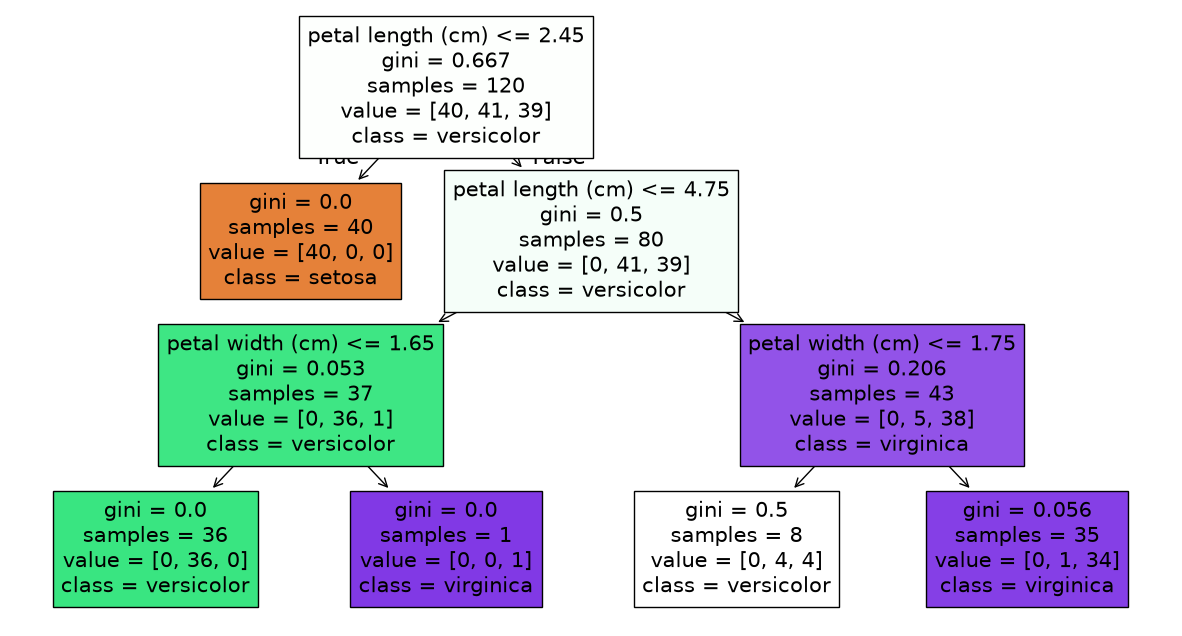

Predicted species: setosa


In [ ]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


# Load the dataset
iris = load_iris()

X = iris.data
y = iris.target


# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# Create the Decision Tree
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)


# Train the model
model.fit(X_train, y_train)


# Make predictions
y_pred = model.predict(X_test)


# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")


# Visualize the tree
plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True
)

plt.show()


# Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)

print("Predicted species:", iris.target_names[prediction[0]])


### The basic machine-learning workflow

This example demonstrates the standard workflow you'll use repeatedly in machine learning:

```
                 Dataset
                    ↓
             Split the data
              ↙          ↘
         Training       Testing
             ↓             ↓
        Train model     Keep aside
             ↓             ↓
          Model ─────→ Predictions
                         ↓
                    Evaluate model
```

The important part to remember is:

```
model.fit(X_train, y_train)       # Learn
model.predict(X_test)             # Predict
accuracy_score(y_test, y_pred)    # Evaluate
```

That three-step pattern — **fit → predict → evaluate** — is fundamental to supervised machine learning.